## 1.1 Windowing synthetic data

Creating the energy matrix

eigenvector [-0.79151878 -0.13650896 -0.28099527 -0.27776256 -0.25493249 -0.26530189
 -0.19595956 -0.15804152]
stability markers [1.1240079627628417, 2.706571006433431, 1.8864725800291733, 1.8974185682446758, 1.98055726175732, 1.9414661554624706, 2.2590028157015625, 2.51544252682064]
number of transform objects (should equal no. windows): 4
windowed data shape (windows,window_size): (4, 176)
actual overlap: 0.20454545454545459
energy matrix shape (nodes_per_packet,windows): (8, 4)
shape of norm_energy_matrix (8, 4)
svd output [[-0.79151878 -0.56944432  0.05449063 -0.02251678 -0.14204721 -0.08786694
  -0.06814317  0.11494975]
 [-0.13650896  0.16798789  0.14902421 -0.03810126  0.08723605 -0.57288617
  -0.31542043 -0.70298415]
 [-0.28099527  0.30685554  0.56941996 -0.26670696 -0.03738509  0.58804531
   0.10832927 -0.26940579]
 [-0.27776256  0.60406269 -0.24563623 -0.05573545 -0.64168894 -0.15782832
  -0.07059558  0.2299009 ]
 [-0.25493249  0.22542615 -0.40722617 -0.59625784  0.58533619 -0

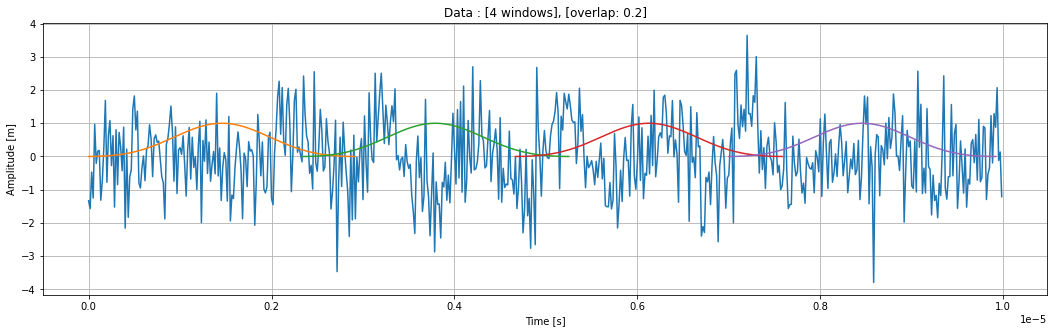

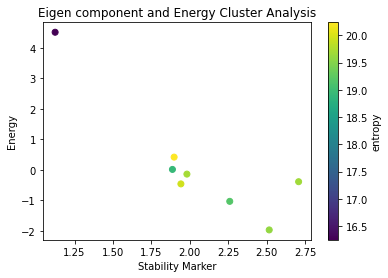

In [6]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv
import numpy as np

import matplotlib.pyplot as plt

amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 60e6 

test_frequencies = [1e6]

for frequency in test_frequencies:
    frequencies = [frequency] # create list of frequencies for synthetic data
    time_period = 1/frequency
    signal_duration = 10*time_period # duration of the signal is 10 times the test frequency
    delay = 2*time_period # signal starts 2 time periods late
    end = 8*time_period # signal ends 2 time periods early

    gaussian_noise_std = 1 # set the standard devaition of the noise

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, signal_duration, 
        sampling_rate, delay, end
        )

    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise

    # transform parameters
    levels = 3
    db_order = 9
    wavelet = f'db{db_order}'

    # create SVD object which windows, transforms, and performs SVD
    windows = 4
    overlap = 0.2
    SVD_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)

    # important parameters
    win_data_shape = SVD_object.windowed_data.shape
    print('number of transform objects (should equal no. windows):',len(SVD_object.transform_objects))
    print('windowed data shape (windows,window_size):',win_data_shape)
    print('actual overlap:',SVD_object.overlap)
    print('energy matrix shape (nodes_per_packet,windows):',SVD_object.energy_matrix.shape)
    print('shape of norm_energy_matrix',SVD_object.norm_energy_matrix.shape)
    print('svd output',SVD_object.svd_matrices[0])
    print('diagonal matrix:',SVD_object.svd_matrices[1])
    print('last matrix:',SVD_object.svd_matrices[2])

    # create plots to show windowed data
    win_len = win_data_shape[1]
    fig1,ax1 = plt.subplots()
    fig1.set_size_inches(18,5)
    plot.plot_wave(data,t_plot,ax1,f': [{windows} windows], [overlap: {round(SVD_object.overlap,2)}]')
    blackman_window = np.blackman(win_len)
    zeros = np.zeros(data.shape)
    offset = 0
    for _ in range(windows):
        time_plot = t_plot[offset:offset+win_len]
        ax1.plot(time_plot,blackman_window)
        offset += SVD_object.offset

    # wpt
    transform_object = wpt.dwpt(data,levels,wavelet)

    # some useful functions
    def compute_shannon_entropy(signal):
        """Here, we will compute nonnormalized shannon entropy.
        We will basically implement MATLAB function 'wentropy'.
        Input: signal should be 1D numpy array."""
        return -np.nansum(signal**2 * np.log(signal**2)) 
    
    def log10_list(input):
        output = []
        for i in input:
            output.append(10*np.log10(i))
        return output
    
    # plot energy, entropy, and stability
    stability_markers = SVD_object.stability_marker

    energy = transform_object.list_energy()
    log_energy = log10_list(energy)

    entropy = []
    for node in transform_object.get_level(): # final level nodes
        nodes4rec = transform_object.packet_nodes_for_rec(levels,keep = [node.path])
        coeffs4rec = transform_object.nodes2data(nodes4rec)
        reconstructed_wave = inv.inv_dwpt(coeffs4rec,wavelet)
        entropy.append(compute_shannon_entropy(reconstructed_wave))
    entropy = log10_list(entropy)

    fig2,ax2 = plt.subplots()
    im = ax2.scatter(stability_markers,log_energy,c=entropy)
    ax2.set_xlabel('Stability Marker')
    ax2.set_ylabel('Energy')
    ax2.set_title('Eigen component and Energy Cluster Analysis')
    fig2.colorbar(im,ax=ax2,label='entropy')
    plt.show()
